In [79]:
import pandas as pd
from sklearn.model_selection import train_test_split

In [80]:
df = pd.read_csv("https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv")
df.head(1)

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1


In [81]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


In [82]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [83]:
categorical_columns = list(df.columns[df.dtypes == "str"])
numerical_columns = list(df.columns[df.dtypes != "str"])

In [84]:
for column in df.columns:
    if column in categorical_columns:
        df[column] = df[column].fillna("NA")
    elif column in numerical_columns:
        df[column] = df[column].fillna(0)

In [85]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

### Question 1

In [86]:
df.industry.value_counts()

industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
NA                240
Name: count, dtype: int64

### Question 2

In [87]:
df[numerical_columns].corr()

,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
annual_income,1.000000,0.161300,0.122842,0.229496,0.189652
number_of_courses_viewed,0.161300,1.000000,0.721609,0.757204,0.395038
interaction_count,0.122842,0.721609,1.000000,0.915746,0.448624
lead_score,0.229496,0.757204,0.915746,1.000000,0.483246
converted,0.189652,0.395038,0.448624,0.483246,1.000000


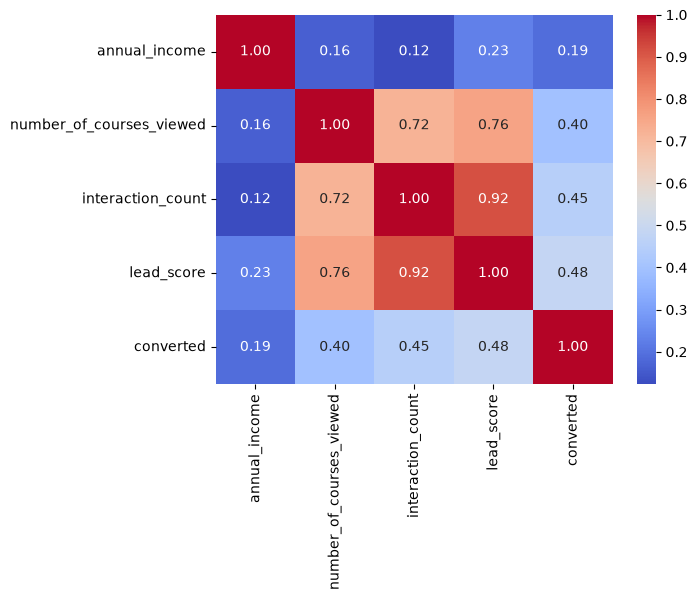

In [88]:
import seaborn as sns

import matplotlib.pyplot as plt

sns.heatmap(df[numerical_columns].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.show()

In [89]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)

In [90]:
y_full_train = df_full_train['converted']
X_full_train = df_full_train.drop(columns=['converted'])

y_train = df_train['converted']
X_train = df_train.drop(columns=['converted'])

y_val = df_val['converted']
X_val = df_val.drop(columns=['converted'])

y_test = df_test['converted']
X_test = df_test.drop(columns=['converted'])

### Question 3

In [91]:
from sklearn.metrics import mutual_info_score

mi_scores = {
    feature: round(mutual_info_score(y_train, X_train[feature]), 2)
    for feature in categorical_columns
}

mi_scores = dict(sorted(mi_scores.items(), key=lambda item: item[1], reverse=True))
mi_scores

{'lead_source': 0.03,
 'employment_status': 0.02,
 'industry': 0.0,
 'location': 0.0}

### Question 4

In [92]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression

numerical_features = X_train.select_dtypes(include="number").columns

preprocessor = ColumnTransformer(
    [
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
        ("numerical", "passthrough", numerical_features),
    ]
)

X_train_encoded = preprocessor.fit_transform(X_train)
X_val_encoded = preprocessor.transform(X_val)

model = LogisticRegression(
    solver="liblinear", C=1.0, max_iter=1000, random_state=42
)
model.fit(X_train_encoded, y_train)

global_accuracy = (y_val == model.predict(X_val_encoded)).mean()
global_accuracy.round(2)

np.float64(0.64)

In [93]:
X_train.head(1)

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score
4702,paid_ads,finance,employed,asia,65980.0,2,3,0.37


### Question 5

In [94]:
for column in X_train.columns:
    X_train_reduced = X_train.drop(columns=[column])
    X_val_reduced = X_val.drop(columns=[column])

    active_categorical_columns = [
        col for col in categorical_columns if col in X_train_reduced.columns
    ]
    numerical_features = X_train_reduced.select_dtypes(include="number").columns

    preprocessor = ColumnTransformer(
        transformers=[
            ("categorical", OneHotEncoder(handle_unknown="ignore"), active_categorical_columns),
            ("numerical", "passthrough", numerical_features),
        ]
    )

    X_train_encoded = preprocessor.fit_transform(X_train_reduced)
    X_val_encoded = preprocessor.transform(X_val_reduced)

    model = LogisticRegression(
        solver="liblinear", C=1.0, max_iter=1000, random_state=42
    )
    model.fit(X_train_encoded, y_train)

    accuracy = (y_val == model.predict(X_val_encoded)).mean()
    print(f"Accuracy without {column}: {accuracy:.3f} and difference with global accuracy: {accuracy - global_accuracy:.3f} ")


Accuracy without lead_source: 0.642 and difference with global accuracy: -0.003 
Accuracy without industry: 0.645 and difference with global accuracy: 0.000 
Accuracy without employment_status: 0.645 and difference with global accuracy: 0.000 
Accuracy without location: 0.645 and difference with global accuracy: 0.000 
Accuracy without annual_income: 0.724 and difference with global accuracy: 0.079 
Accuracy without number_of_courses_viewed: 0.643 and difference with global accuracy: -0.002 
Accuracy without interaction_count: 0.601 and difference with global accuracy: -0.044 
Accuracy without lead_score: 0.644 and difference with global accuracy: -0.001 


### Question 6

In [ ]:
numerical_features = X_train.select_dtypes(include="number").columns

regularized_preprocessor = ColumnTransformer(
    [
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
        ("numerical", "passthrough", numerical_features),
    ]
)

X_train_all = regularized_preprocessor.fit_transform(X_train)
X_val_all = regularized_preprocessor.transform(X_val)

for C in [0.000001, 0.00001, 0.0001, 0.001]:
    regularized_model = LogisticRegression(
        solver="liblinear", C=C, max_iter=1000, random_state=42
    )
    regularized_model.fit(X_train_all, y_train)

    accuracy = (y_val == regularized_model.predict(X_val_all)).mean()
    print(f"C={C}: accuracy={accuracy:.3f}")